<h2 style="color:darkblue> # **Student Performance Analysis- Project 1**</h2>


# **Student Performance Analysis Using Python**

## Project Overview
This project analyzes student academic performance and attendance using Python. The analysis includes data inspection, data cleaning, exploratory data analysis (EDA), and visualization to identify patterns in marks, pass/fail results, subject performance, and department performance.

## 01. Project Objective
The objectives of this project are to:

- Inspect and clean student performance data.
- Identify missing values, invalid entries, and duplicate records.
- Analyze student marks and pass/fail percentages.
- Compare average marks across subjects and departments.
- Examine student attendance patterns.
- Identify top-performing students.
- Present key findings through meaningful visualizations.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

In [534]:
# import warnings
import warnings
warnings.filterwarnings("ignore")

 ### **Load the Dataset**

In [537]:
# Import the Library
import pandas as pd
import numpy as np

In [539]:
# Read the csv Dataset
df = pd.read_csv("Student_Performance_Messy.csv")


In [541]:
# Display the complete dataset
df

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
0,1,Student_001,Male,ECE,100.0,49,NaN,70.0,Pass
1,2,Student_002,Male,CSE,68.0,48,46.0,89.0,Fail
2,3,Student_003,Male,CIVIL,65.0,62,64.0,99.0,Fail
3,4,Student_004,Female,CSE,72.0,88,63.0,92.0,Fail
4,5,Student_005,Male,ECE,70.0,89,78.0,70.0,Fail
...,...,...,...,...,...,...,...,...,...
515,219,Student_219,Female,CSE,61.0,76,56.0,93.0,Fail
516,89,Student_089,Female,EEE,77.0,90,97.0,38.0,Pass
517,182,Student_182,Female,ECE,94.0,80,42.0,85.0,Pass
518,110,Student_110,Female,ECE,61.0,46,72.0,63.0,Fail


### **Inspect the data**

In [544]:
# Inspect the data 
# Display the First 5 Rows 
df.head()


,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
0,1,Student_001,Male,ECE,100.0,49,NaN,70.0,Pass
1,2,Student_002,Male,CSE,68.0,48,46.0,89.0,Fail
2,3,Student_003,Male,CIVIL,65.0,62,64.0,99.0,Fail
3,4,Student_004,Female,CSE,72.0,88,63.0,92.0,Fail
4,5,Student_005,Male,ECE,70.0,89,78.0,70.0,Fail


In [546]:
# Display the Last 5 Rows 
df.tail()


,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
515,219,Student_219,Female,CSE,61.0,76,56.0,93.0,Fail
516,89,Student_089,Female,EEE,77.0,90,97.0,38.0,Pass
517,182,Student_182,Female,ECE,94.0,80,42.0,85.0,Pass
518,110,Student_110,Female,ECE,61.0,46,72.0,63.0,Fail
519,466,Student_466,Male,CSE,64.0,51,63.0,91.0,Fail


In [548]:
df.tail(20)

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
500,22,Student_022,Male,CIVIL,98.0,60,54.0,82.0,Pass
501,483,Student_483,Male,CSE,97.0,43,74.0,90.0,Pass
502,237,Student_237,Female,CIVIL,84.0,77,51.0,46.0,Pass
503,26,Student_026,Male,CIVIL,90.0,56,68.0,89.0,Pass
504,87,Student_087,Male,EEE,84.0,37,83.0,96.0,Pass
505,474,Student_474,Male,CIVIL,95.0,71,38.0,73.0,Pass
506,294,Student_294,Female,MECH,100.0,38,98.0,72.0,Pass
507,222,Student_222,Male,EEE,70.0,44,100.0,49.0,Fail
508,421,Student_421,Male,EEE,62.0,81,45.0,48.0,Fail
509,371,Student_371,Female,EEE,72.0,62,96.0,61.0,Fail


In [550]:
# Find the Shape of the Dataset(Find the number of rows and columns)
df.shape

(520, 9)

In [552]:
# Number of Rows
df.shape[0]

520

In [554]:
# number of columns
df.shape[1]

9

In [556]:
# To find the index
df.index

RangeIndex(start=0, stop=520, step=1)

In [558]:
# Display Data Types
df.dtypes

Student_ID         int64
Student_Name      object
Gender            object
Department        object
Attendance       float64
Math_Score        object
Science_Score    float64
English_Score    float64
Final_Result      object
dtype: object

In [560]:
# Display Column Names 
df.columns

Index(['Student_ID', 'Student_Name', 'Gender', 'Department', 'Attendance',
       'Math_Score', 'Science_Score', 'English_Score', 'Final_Result'],
      dtype='object')

In [562]:
# display only numeric columns
df.select_dtypes(include='number').columns

Index(['Student_ID', 'Attendance', 'Science_Score', 'English_Score'], dtype='object')

In [564]:
# Display only non numeric column/ categorical columns
df.select_dtypes(exclude='number').columns

Index(['Student_Name', 'Gender', 'Department', 'Math_Score', 'Final_Result'], dtype='object')

In [566]:
# Display complete information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Student_ID     520 non-null    int64  
 1   Student_Name   520 non-null    object 
 2   Gender         512 non-null    object 
 3   Department     520 non-null    object 
 4   Attendance     511 non-null    float64
 5   Math_Score     511 non-null    object 
 6   Science_Score  511 non-null    float64
 7   English_Score  516 non-null    float64
 8   Final_Result   520 non-null    object 
dtypes: float64(3), int64(1), object(5)
memory usage: 36.7+ KB


In [568]:
df['Math_Score']=pd.to_numeric(df['Math_Score'],errors ='coerce')
df # incorrect data 90 instead ninety is present so it is object type so we convert into nan.  If you cannot convert a value into a number, replace it with NaN."

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
0,1,Student_001,Male,ECE,100.0,49.0,NaN,70.0,Pass
1,2,Student_002,Male,CSE,68.0,48.0,46.0,89.0,Fail
2,3,Student_003,Male,CIVIL,65.0,62.0,64.0,99.0,Fail
3,4,Student_004,Female,CSE,72.0,88.0,63.0,92.0,Fail
4,5,Student_005,Male,ECE,70.0,89.0,78.0,70.0,Fail
...,...,...,...,...,...,...,...,...,...
515,219,Student_219,Female,CSE,61.0,76.0,56.0,93.0,Fail
516,89,Student_089,Female,EEE,77.0,90.0,97.0,38.0,Pass
517,182,Student_182,Female,ECE,94.0,80.0,42.0,85.0,Pass
518,110,Student_110,Female,ECE,61.0,46.0,72.0,63.0,Fail


Attribute Stores information about an object.- Accessed without parentheses () eg. df.columns
Method-Performs an action or operation.Called with parentheses ()- df.head()
function : pd.read_csv() - Function (belongs to the Pandas library)

In [571]:
# Statistical Summary
df.describe()

,Student_ID,Attendance,Math_Score,Science_Score,English_Score
count,520.000000,511.000000,510.000000,511.000000,516.000000
mean,249.948077,80.778865,67.076471,67.414873,69.542636
std,144.683440,14.358438,21.943937,18.802797,19.008024
min,1.000000,-5.000000,-10.000000,35.000000,35.000000
25%,124.750000,71.000000,50.000000,51.000000,53.000000
50%,248.500000,81.000000,69.000000,68.000000,70.500000
75%,374.250000,91.000000,85.000000,84.000000,87.000000
max,500.000000,120.000000,150.000000,100.000000,100.000000


min and max in attendance is error
math score  -ve 
science and english blank is possible


df.describe() - default describe(include =None)  # Display summary statistics for numerical columns
df.describe(include ='all')  # display all column numerical and categorical 

### **Finding the missing value**

In [576]:
# Check Missing Values
df.isnull()

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
0,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
515,False,False,False,False,False,False,False,False,False
516,False,False,False,False,False,False,False,False,False
517,False,False,False,False,False,False,False,False,False
518,False,False,False,False,False,False,False,False,False


In [578]:
# count Missing Values
df.isnull().sum() # isnull present true count that value

Student_ID        0
Student_Name      0
Gender            8
Department        0
Attendance        9
Math_Score       10
Science_Score     9
English_Score     4
Final_Result      0
dtype: int64

### **Finding the duplicates and remove those duplicates and null value handling**

In [581]:
# Count Duplicate Records 
df.duplicated().sum()

20

Checking Duplicate Student Records

The Student_ID column is used to identify repeated student records. Duplicate IDs are inspected before removing records because repeated IDs may indicate accidental duplicate entries or may represent legitimate records from different exams or terms.

Only confirmed duplicate records should be removed to avoid losing valid student information.

In [584]:
# Remove duplicate records permanently
df = df.drop_duplicates()

In [586]:
# Count Duplicate Records 
df.duplicated().sum()

0

In [588]:
# shape of the dataset
df.shape

(500, 9)

In [590]:
# Find Unique Gender Values
#  Display all unique values in the Gender column
df["Gender"].unique() 

array(['Male', 'Female', ' male ', nan, 'Mle', 'Femle', 'FEMALE '],
      dtype=object)

In [592]:
# Count Each Gender
# Count the frequency of each gender
df["Gender"].value_counts()

Gender
Female     255
Male       227
 male        4
Femle        3
Mle          2
FEMALE       1
Name: count, dtype: int64

In [594]:
# Number of Unique Genders
# Count unique gender values
df["Gender"].nunique()

6

In [596]:
df["Gender"] = df["Gender"].replace({
    "Mle": "Male",
    "Femle": "Female",
    " male ": "Male",
    "FEMALE ": "Female"
})

In [598]:
# Correct Gender Values
df["Gender"].unique()

array(['Male', 'Female', nan], dtype=object)

In [600]:
df["Gender"].isnull().sum()

8

Handling Missing Gender Values

Missing gender values are replaced with Unknown to preserve student records without assuming or guessing a student's gender.

The Unknown category indicates that gender information was not available or could not be reliably identified. This approach preserves the records while maintaining transparency in data cleaning.

During analysis, Unknown is treated as a separate category and is included in gender distribution counts.

In [603]:
# missing value handling
df["Gender"] = df["Gender"].fillna("Unknown")

Fill with Mode (Recommended)	df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])	Most common method for categorical data.
2. Fill with "Unknown"	df["Gender"] = df["Gender"].fillna("Unknown")	When you don't want to guess the missing value.
3. Fill with a Fixed Value	df["Gender"] = df["Gender"].fillna("Not Available")	Used for reports or user-facing datasets.
4. Forward Fill (ffill)	df["Gender"] = df["Gender"].ffill()	Copies the previous row's value. Useful for time-series or grouped data.
5. Backward Fill (bfill)	df["Gender"] = df["Gender"].bfill()	Copies the next row's value.
6. Drop Missing Rows	df = df.dropna(subset=["Gender"])	When only a few rows are missing

In [606]:
# Find the missing values
df.isnull().sum()

Student_ID        0
Student_Name      0
Gender            0
Department        0
Attendance        9
Math_Score       10
Science_Score     9
English_Score     4
Final_Result      0
dtype: int64

# Handle Missing Values 
Marks below 0 or above 100 are treated as invalid because they fall outside the expected marks range. Attendance below 0% or above 100% is also invalid.

These values are converted to missing values (NaN) so that they can be investigated and handled appropriately instead of affecting the analysis.

Note: This assumes each subject is graded out of 100 and attendance is recorded as a percentage.

In [612]:
df["Attendance"] > 100

0      False
1      False
2      False
3      False
4      False
       ...  
495    False
496    False
497    False
498    False
499    False
Name: Attendance, Length: 500, dtype: bool

In [614]:
df[df["Attendance"] > 100]

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
127,128,Student_128,Male,EEE,120.0,89.0,49.0,63.0,Fail
207,208,Student_208,Male,CSE,120.0,82.0,74.0,76.0,Fail
231,232,Student_232,Female,EEE,120.0,91.0,91.0,55.0,Pass
281,282,Student_282,Male,ECE,120.0,43.0,72.0,73.0,Pass
284,285,Student_285,Female,MECH,120.0,51.0,46.0,43.0,Pass
383,384,Student_384,Male,CIVIL,120.0,96.0,97.0,37.0,Pass
437,438,Student_438,Male,CIVIL,120.0,49.0,58.0,82.0,Pass
487,488,Student_488,Female,CIVIL,120.0,38.0,77.0,89.0,Fail


In [616]:
invalid_attendance = df[df["Attendance"] > 100]

print(invalid_attendance)

print("Number of invalid records:", len(invalid_attendance))



     Student_ID Student_Name  Gender Department  Attendance  Math_Score  \
127         128  Student_128    Male        EEE       120.0        89.0   
207         208  Student_208    Male        CSE       120.0        82.0   
231         232  Student_232  Female        EEE       120.0        91.0   
281         282  Student_282    Male        ECE       120.0        43.0   
284         285  Student_285  Female       MECH       120.0        51.0   
383         384  Student_384    Male      CIVIL       120.0        96.0   
437         438  Student_438    Male      CIVIL       120.0        49.0   
487         488  Student_488  Female      CIVIL       120.0        38.0   

     Science_Score  English_Score Final_Result  
127           49.0           63.0         Fail  
207           74.0           76.0         Fail  
231           91.0           55.0         Pass  
281           72.0           73.0         Pass  
284           46.0           43.0         Pass  
383           97.0           3

In [618]:


df.loc[df["Attendance"] > 100, "Attendance"] = np.nan
# It replaces only the invalid Attendance values (greater than 100) with NaN.

In [620]:
df[df["Attendance"] > 100]

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result


In [622]:
#Check Missing Values
df["Attendance"].isnull().sum()

17

In [624]:
#Fill Missing Values
df["Attendance"] = df["Attendance"].fillna(df["Attendance"].median())

In [626]:
# verify again
df["Attendance"].isnull().sum()

0

In [628]:
# Attendance < 0
df[df["Attendance"] < 0]

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
15,16,Student_016,Male,CIVIL,-5.0,86.0,81.0,63.0,Pass
48,49,Student_049,Female,CIVIL,-5.0,NaN,71.0,55.0,Pass


In [630]:
invalid_attendance = df[df["Attendance"] < 0]

print(invalid_attendance)

print("Number of invalid records:", len(invalid_attendance))


    Student_ID Student_Name  Gender Department  Attendance  Math_Score  \
15          16  Student_016    Male      CIVIL        -5.0        86.0   
48          49  Student_049  Female      CIVIL        -5.0         NaN   

    Science_Score  English_Score Final_Result  
15           81.0           63.0         Pass  
48           71.0           55.0         Pass  
Number of invalid records: 2


In [632]:
import numpy as np

df.loc[df["Attendance"] < 0, "Attendance"] = np.nan
# It replaces only the invalid Attendance values (greater than 100) with NaN.

In [634]:
#Check Missing Values
df["Attendance"].isnull().sum()

2

In [636]:
#Fill Missing Values
df["Attendance"] = df["Attendance"].fillna(df["Attendance"].median())

In [638]:
df["Attendance"].isnull().sum()

0

In [640]:
df[df["Math_Score"] < 0]

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
190,191,Student_191,Male,MECH,62.0,-10.0,93.0,NaN,Fail
298,299,Student_299,Male,ECE,89.0,-10.0,69.0,92.0,Pass
300,301,Student_301,Male,MECH,70.0,-10.0,75.0,59.0,Fail
322,323,Student_323,Female,MECH,79.0,-10.0,61.0,97.0,Pass
351,352,Student_352,Female,MECH,87.0,-10.0,43.0,42.0,Pass
469,470,Student_470,Female,ECE,64.0,-10.0,56.0,91.0,Fail
480,481,Student_481,Male,EEE,85.0,-10.0,54.0,70.0,Pass


In [642]:
# Replace negative Math_Score values with NaN
df.loc[df["Math_Score"] < 0, "Math_Score"] = np.nan
#df.loc[condition, column] = new_value
# Replace only negative Math_Score values with NaN.

In [644]:
df[df["Math_Score"] > 100]

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
43,44,Student_044,Female,CIVIL,67.0,150.0,40.0,45.0,Fail
132,133,Student_133,Male,ECE,65.0,150.0,37.0,69.0,Fail


In [646]:
df.loc[df["Math_Score"] > 100, "Math_Score"] = np.nan

Missing values may occur when marks or attendance are unavailable or when invalid values are converted to NaN.

Mean: Used to fill missing numerical values when the data does not contain strong outliers and the average is representative.

Median: Used when the data contains outliers or is skewed because it is less affected by extreme values.

These methods help retain records for analysis. However, the filled values are estimates, not the student's actual marks or attendance.

In [649]:
# Fill missing Math_Score with mean
df["Math_Score"] = df["Math_Score"].fillna(df["Math_Score"].mean())

In [651]:
# Fill missing Science_Score with mean
df["Science_Score"] = df["Science_Score"].fillna(df["Science_Score"].mean())

In [653]:
# Fill missing English_Score with mean
df["English_Score"] = df["English_Score"].fillna(df["English_Score"].mean())

In [655]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Student_ID     500 non-null    int64  
 1   Student_Name   500 non-null    object 
 2   Gender         500 non-null    object 
 3   Department     500 non-null    object 
 4   Attendance     500 non-null    float64
 5   Math_Score     500 non-null    float64
 6   Science_Score  500 non-null    float64
 7   English_Score  500 non-null    float64
 8   Final_Result   500 non-null    object 
dtypes: float64(4), int64(1), object(4)
memory usage: 39.1+ KB


In [657]:
df.describe()

,Student_ID,Attendance,Math_Score,Science_Score,English_Score
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,80.656000,67.966736,67.437882,69.431452
std,144.481833,11.642369,19.149526,18.535935,18.985369
min,1.000000,60.000000,35.000000,35.000000,35.000000
25%,125.750000,71.000000,51.000000,51.000000,53.000000
50%,250.500000,81.000000,67.983368,67.718941,70.000000
75%,375.250000,90.000000,85.000000,83.250000,86.250000
max,500.000000,100.000000,100.000000,100.000000,100.000000


"Our data is clean. Now we can answer business questions using this data."
gender male vs female
pass and fail percentage
attendance 
top performer
poor performer
which department perform well

In [660]:
# # Gender   - how many male and female students are there in this college?

df['Gender'].value_counts()

Gender
Female     259
Male       233
Unknown      8
Name: count, dtype: int64

In [662]:
# Total Students
df.shape

(500, 9)

In [664]:
total_students= len(df) #  len(studentid)
total_students

500

How many students passed?
How many students failed?
Which group is larger?

In [667]:
# Pass vs Fail
df["Final_Result"].value_counts()

Final_Result
Pass    324
Fail    176
Name: count, dtype: int64

In [669]:
pass_count = (df["Final_Result"] == "Pass").sum()
pass_count

324

In [671]:
# Pass Percentage
pass_percentage = (pass_count / total_students) * 100

print(pass_percentage)

64.8


In [673]:
# Department-wise Students
df["Department"].value_counts()

Department
EEE      112
CSE      105
CIVIL     99
ECE       93
MECH      91
Name: count, dtype: int64

Which department has the most students?
Which department has the fewest students?

In [676]:
# Average Marks
df[["Math_Score", "Science_Score", "English_Score"]].mean()

Math_Score       67.966736
Science_Score    67.437882
English_Score    69.431452
dtype: float64

Which subject has the highest average score?
Which subject has the lowest average score?

In [679]:
# df["Math_Score"].mean()

In [681]:
#Calculate Average Attendance
df['Attendance'].mean().round(2)

80.66

In [683]:
# minimum attendance
df["Attendance"].max()

100.0

In [685]:
# maximum attendance
df["Attendance"].min()

60.0

In [687]:
# Students with attendance equal to 60%
df[df["Attendance"] == 60]

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
117,118,Student_118,Female,EEE,60.0,71.0,95.000000,96.0,Fail
161,162,Student_162,Male,MECH,60.0,94.0,71.000000,55.0,Fail
185,186,Student_186,Female,ECE,60.0,70.0,53.000000,51.0,Fail
333,334,Student_334,Female,MECH,60.0,73.0,48.000000,77.0,Fail
371,372,Student_372,Female,ECE,60.0,62.0,59.000000,50.0,Fail
381,382,Student_382,Male,ECE,60.0,87.0,52.000000,64.0,Fail
382,383,Student_383,Female,CSE,60.0,62.0,67.437882,93.0,Fail
422,423,Student_423,Male,MECH,60.0,47.0,68.000000,63.0,Fail
491,492,Student_492,Female,MECH,60.0,66.0,40.000000,95.0,Fail


In [689]:
df[(df["Attendance"] >= 70) & (df["Attendance"] <= 80)]

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
3,4,Student_004,Female,CSE,72.0,88.0,63.0,92.0,Fail
4,5,Student_005,Male,ECE,70.0,89.0,78.0,70.0,Fail
8,9,Student_009,Male,MECH,74.0,72.0,45.0,64.0,Fail
9,10,Student_010,Female,EEE,77.0,93.0,81.0,55.0,Pass
10,11,Student_011,Male,ECE,73.0,69.0,44.0,56.0,Fail
...,...,...,...,...,...,...,...,...,...
475,476,Student_476,Male,MECH,75.0,98.0,84.0,49.0,Pass
483,484,Student_484,Female,CIVIL,75.0,46.0,90.0,49.0,Pass
490,491,Student_491,Male,CSE,76.0,48.0,49.0,64.0,Pass
493,494,Student_494,Male,CIVIL,75.0,88.0,75.0,69.0,Pass


In [691]:
# How many students have attendance less than 80%?
len(df[df["Attendance"] < 80])

225

In [693]:
# Students with attendance above 90%
df[df["Attendance"] > 90]

,Student_ID,Student_Name,Gender,Department,Attendance,Math_Score,Science_Score,English_Score,Final_Result
0,1,Student_001,Male,ECE,100.0,49.0,67.437882,70.0,Pass
16,17,Student_017,Male,ECE,91.0,46.0,41.000000,49.0,Pass
20,21,Student_021,Male,CIVIL,92.0,57.0,99.000000,48.0,Pass
21,22,Student_022,Male,CIVIL,98.0,60.0,54.000000,82.0,Pass
22,23,Student_023,Unknown,CSE,93.0,35.0,76.000000,97.0,Pass
...,...,...,...,...,...,...,...,...,...
476,477,Student_477,Female,ECE,100.0,44.0,36.000000,81.0,Pass
482,483,Student_483,Male,CSE,97.0,43.0,74.000000,90.0,Pass
484,485,Student_485,Male,CSE,98.0,42.0,74.000000,57.0,Pass
486,487,Student_487,Male,EEE,93.0,68.0,56.000000,82.0,Pass


In [695]:
len(df[df["Attendance"] > 90])

120

In [697]:
#Display Highest and Lowest Marks
print("Highest Math Score:", df["Math_Score"].max())
print("Highest Science Score:", df["Science_Score"].max())
print("Highest English Score:", df["English_Score"].max())


Highest Math Score: 100.0
Highest Science Score: 100.0
Highest English Score: 100.0


In [699]:
# Lowest marks in each subject
print("Lowest Math Score:", df["Math_Score"].min())
print("Lowest Science Score:", df["Science_Score"].min())
print("Lowest English Score:", df["English_Score"].min())

Lowest Math Score: 35.0
Lowest Science Score: 35.0
Lowest English Score: 35.0


In [701]:
# Calculate Total Marks
df["Total_Marks"] = (df["Math_Score"] + df["Science_Score"] + df["English_Score"])
df["Total_Marks"]

0      186.437882
1      183.000000
2      225.000000
3      243.000000
4      237.000000
          ...    
495    169.000000
496    215.000000
497    211.000000
498    224.000000
499    181.000000
Name: Total_Marks, Length: 500, dtype: float64

In [703]:
# Top 10 students based on Total Marks
top10 = df.nlargest(10, "Total_Marks")

print(top10[["Student_Name", "Department","Math_Score", "Science_Score",
             "English_Score", "Total_Marks"]])

    Student_Name Department  Math_Score  Science_Score  English_Score  \
309  Student_310        CSE       100.0           86.0           99.0   
419  Student_420      CIVIL        96.0           86.0           99.0   
37   Student_038       MECH        87.0           97.0           96.0   
103  Student_104        EEE        96.0           94.0           90.0   
423  Student_424        EEE        85.0           94.0           99.0   
228  Student_229       MECH        99.0           84.0           94.0   
302  Student_303        ECE        85.0           99.0           93.0   
209  Student_210        ECE        97.0           91.0           88.0   
442  Student_443        CSE        88.0           91.0           97.0   
295  Student_296        ECE        91.0           88.0           96.0   

     Total_Marks  
309        285.0  
419        281.0  
37         280.0  
103        280.0  
423        278.0  
228        277.0  
302        277.0  
209        276.0  
442        276.0  
295   

In [705]:
# Bottom 10 students based on Total Marks
top10 = df.nsmallest(10, "Total_Marks")

print(top10[["Student_Name", "Department","Math_Score", "Science_Score",
             "English_Score","Total_Marks"]])

    Student_Name Department  Math_Score  Science_Score  English_Score  \
94   Student_095        ECE        43.0           40.0           38.0   
36   Student_037        ECE        47.0           41.0           36.0   
186  Student_187        ECE        38.0           51.0           36.0   
464  Student_465       MECH        46.0           47.0           35.0   
54   Student_055      CIVIL        36.0           49.0           44.0   
33   Student_034        EEE        41.0           47.0           42.0   
74   Student_075       MECH        53.0           38.0           40.0   
124  Student_125       MECH        44.0           55.0           35.0   
16   Student_017        ECE        46.0           41.0           49.0   
390  Student_391       MECH        36.0           56.0           45.0   

     Total_Marks  
94         121.0  
36         124.0  
186        125.0  
464        128.0  
54         129.0  
33         130.0  
74         131.0  
124        134.0  
16         136.0  
390   

Who scored highest?
Which department has more top performers?

In [708]:
# Average marks by department
df.groupby("Department")["Total_Marks"].mean()

Department
CIVIL    204.340163
CSE      208.564514
ECE      201.216926
EEE      205.930423
MECH     203.425308
Name: Total_Marks, dtype: float64

In [710]:
df.groupby("Department")["Total_Marks"].mean().round().astype(int)

Department
CIVIL    204
CSE      209
ECE      201
EEE      206
MECH     203
Name: Total_Marks, dtype: int32

### **Charts** 

In [713]:
import matplotlib.pyplot as plt

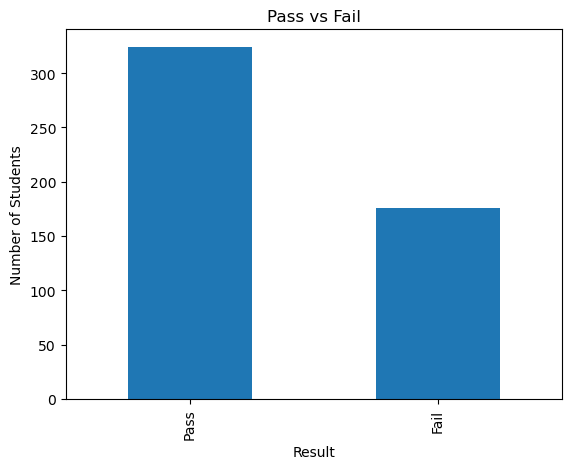

In [715]:
# Pass vs Fail
df["Final_Result"].value_counts().plot(kind="bar")
plt.title("Pass vs Fail")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.show()

plt.title("Pass vs Fail")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.show()

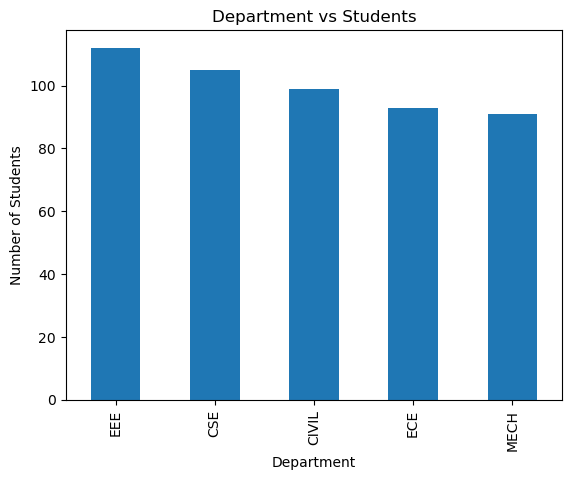

In [718]:
# Department-wise Students
df["Department"].value_counts().plot(kind="bar")
plt.title("Department vs Students")
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.show()

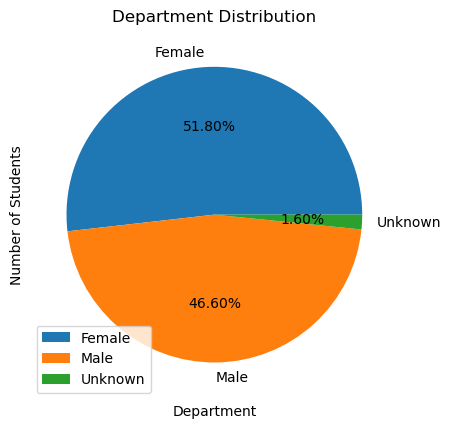

In [720]:
#Gender Distribution
df["Gender"].value_counts().plot(kind="pie",autopct="%1.2f%%")
plt.title("Department Distribution")
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.legend()
plt.show()


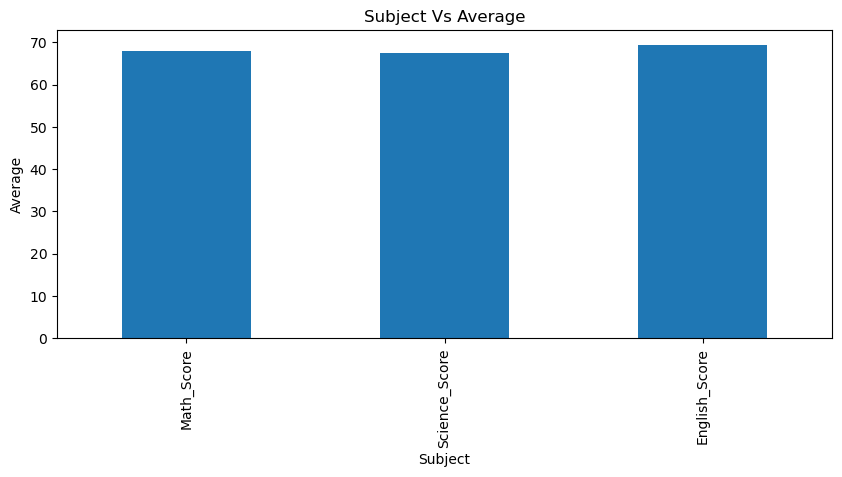

In [722]:
# Average Subject Marks
Average_Marks=df[["Math_Score","Science_Score","English_Score"]].mean().plot(kind="bar",figsize=(10,4))
plt.title("Subject Vs Average")
plt.xlabel("Subject")
plt.ylabel("Average")
plt.show()

In [724]:
df["Attendance"]

0      100.0
1       68.0
2       65.0
3       72.0
4       70.0
       ...  
495     93.0
496     79.0
497     81.0
498     81.0
499     86.0
Name: Attendance, Length: 500, dtype: float64

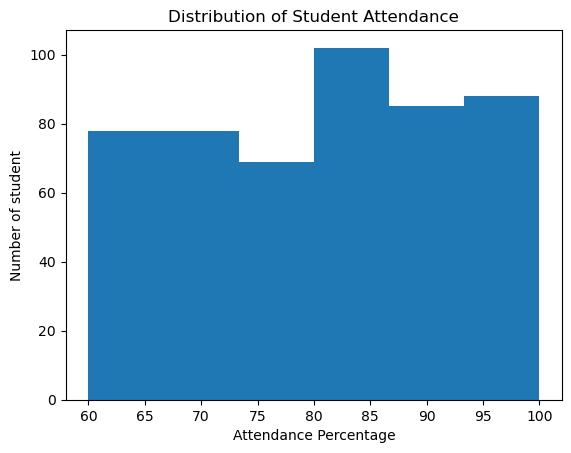

In [726]:
# Attendance Distribution
df["Attendance"].plot(kind="hist",bins=6)
plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance Percentage")
plt.ylabel("Number of student")
plt.show()

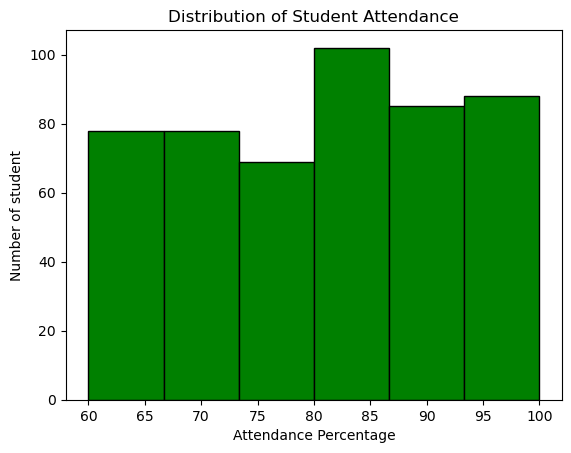

In [728]:
# Attendance Distribution
df["Attendance"].plot(kind="hist",bins=6,edgecolor="black",color="green",linewidth =1)
plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance Percentage")
plt.ylabel("Number of student")
plt.show()

Findings from your project
Analysis	Your result
Students analyzed after duplicate removal	500
Students passed	324 (64.8%)
Students failed	176 (35.2%)
Strongest subject by average marks	English — 69.43/100
Department with highest average total marks	CSE — 208.56/300
Average attendance	80.66%
Students with attendance below 80%	225 (45%)
Students with attendance above 90%	120 (24%)
Highest-scoring student	Student_310 — 285/300

In [731]:
# Overall pass and fail percentages
total_students = len(df)

result_counts = df["Final_Result"].value_counts()
pass_count = result_counts.get("Pass", 0)
fail_count = result_counts.get("Fail", 0)

print(f"Total students: {total_students}")
print(f"Passed: {pass_count} ({pass_count / total_students * 100:.2f}%)")
print(f"Failed: {fail_count} ({fail_count / total_students * 100:.2f}%)")

# Average marks by subject
subject_columns = ["Math_Score", "Science_Score", "English_Score"]
subject_averages = df[subject_columns].mean().sort_values(ascending=False)

print("\nAverage marks by subject:")
print(subject_averages.round(2))

# Average total marks by department
department_averages = (
    df.groupby("Department")["Total_Marks"]
    .mean()
    .sort_values(ascending=False)
)

print("\nAverage total marks by department:")
print(department_averages.round(2))

# Attendance analysis
print(f"\nAverage attendance: {df['Attendance'].mean():.2f}%")
print(f"Students below 80% attendance: {(df['Attendance'] < 80).sum()}")
print(f"Students above 90% attendance: {(df['Attendance'] > 90).sum()}")

# Top 3 performers
print("\nTop 3 performers:")
print(
    df.nlargest(3, "Total_Marks")[
        ["Student_Name", "Department", "Total_Marks"]
    ].to_string(index=False)
)

Total students: 500
Passed: 324 (64.80%)
Failed: 176 (35.20%)

Average marks by subject:
English_Score    69.43
Math_Score       67.97
Science_Score    67.44
dtype: float64

Average total marks by department:
Department
CSE      208.56
EEE      205.93
CIVIL    204.34
MECH     203.43
ECE      201.22
Name: Total_Marks, dtype: float64

Average attendance: 80.66%
Students below 80% attendance: 225
Students above 90% attendance: 120

Top 3 performers:
Student_Name Department  Total_Marks
 Student_310        CSE        285.0
 Student_420      CIVIL        281.0
 Student_038       MECH        280.0


# Final Findings and Conclusion

## Key Findings

### 1. Student Pass and Fail Analysis
Out of 500 students, 324 students passed and 176 students failed. The overall pass percentage is 64.8%, while the failure percentage is 35.2%.

### 2. Subject Performance
English recorded the highest average score at approximately 69.43 marks, followed by Mathematics at 67.97 marks and Science at 67.44 marks. English was the strongest subject based on average marks.

### 3. Department Performance
The CSE department recorded the highest average total marks, approximately 208.56 out of 300. EEE followed with 205.93 marks. ECE recorded the lowest department average at approximately 201.22 marks.

### 4. Attendance Analysis
The average student attendance was 80.66%. A total of 225 students had attendance below 80%, while 120 students had attendance above 90%. These results highlight differences in student attendance patterns.

### 5. Top Performers
Student_310 from CSE achieved the highest total score of 285 out of 300. Student_420 from CIVIL scored 281, and Student_038 from MECH scored 280.

## Conclusion
The analysis shows an overall pass rate of 64.8%, with English having the highest average subject score and CSE achieving the highest average total marks among departments. Attendance varied across students, with 45% recording attendance below 80%.

These findings provide a useful overview of academic performance and attendance. Further analysis could investigate whether attendance is associated with academic results and identify areas where students may benefit from additional academic support.